In [98]:
from typing import TypedDict, Literal

class Ingredient(TypedDict):
    name: str
    amount: float
    unit: str
    flavour: Literal[
        'acidity', 'salt', 'spice', 'bitter', 
        'creamy', 'sweet', 'none', 'aromatic'
        ]
    type: Literal[
        'starches', 'sugars', 'salts', 'fats', 
        'seeds_nuts_dried_fruits', 'binders', 
        'produce', 'spices', 'sugars', 'liquids'
        ]
    ingredients: list[Ingredient]
    cons: Literal["SOLID", "LIQUID"]
    is_indonesian: bool
    fitness: float

class Recipe(TypedDict):
    name: str
    servings: int
    ingredients: list[Ingredient]
    source: str

In [99]:
%pip install pandas

import pprint
import json
from pathlib import Path
import pandas as pd
from typing import Any, cast


def load_json_file(path: str | Path) -> list[Recipe]:
    json_path = Path(path)

    if not json_path.exists():
        raise FileNotFoundError(f"File not found: {json_path.resolve()}")

    text = json_path.read_text(encoding="utf-8").strip()
    if not text:
        raise ValueError(f"JSON file is empty: {json_path.resolve()}")

    try:
        data: Any = json.loads(text)
    except json.JSONDecodeError as error:
        raise ValueError(
            f"Invalid JSON in {json_path.resolve()} "
            f"at line {error.lineno}, column {error.colno}"
        ) from error

    if isinstance(data, list):
        return cast(list[Recipe], data)

    if isinstance(data, dict) and isinstance(data.get("results"), list):
        return cast(list[Recipe], data["results"])

    raise ValueError(
        f"Expected a JSON list or an object containing a 'results' list: "
        f"{json_path.resolve()}"
    )


def find_and_replace_recipe_properties(
    inspiring_set: list[Recipe],
    replacement_data: pd.DataFrame,
    target_properties: list[str] | None = None,
    reference_column: str = "ingredient",
) -> list[Recipe]:
    properties = target_properties or ["flavour", "type", "is_indonesian"]

    if reference_column not in replacement_data.columns:
        raise KeyError(
            f"Column {reference_column!r} not found in metadata. "
            f"Available columns: {list(replacement_data.columns)}"
        )

    for recipe in inspiring_set:
        for ingredient in recipe["ingredients"]:
            ingredient_name = ingredient.get("name")
            if not ingredient_name:
                continue

            matching_rows = replacement_data[
                replacement_data[reference_column] == ingredient_name
            ]

            if matching_rows.empty:
                continue

            row = matching_rows.iloc[0]
            for prop in properties:
                if prop in matching_rows.columns and pd.notna(row[prop]):
                    value = row[prop]
                    ingredient[prop] = value.item() if hasattr(value, 'item') else value

    return inspiring_set


ingredient_metadata = pd.read_csv("data/ingredient_classification.csv")

# Inspring set based on western recipes and indonesian drinks and baked goods
inspiring_set = find_and_replace_recipe_properties(load_json_file("data/inspiring_set.json"), ingredient_metadata);
western_recipes = find_and_replace_recipe_properties(load_json_file("data/western_cookies.json"), ingredient_metadata);

def json_default(value):
    if hasattr(value, "item"):
        return value.item()
    raise TypeError(f"Object of type {type(value).__name__} is not JSON serializable")





Note: you may need to restart the kernel to use updated packages.


In [100]:
#normalising data: adding sources & converting units (tsp/tbsp/cups/eggs...) to g or ml

# Synonyms are merged into one name so they are treated as the same ingredient
# (e.g. "cinnamon" + "ground cinnamon" no longer both end up in one recipe).
CANONICAL_NAMES: dict[str, str] = {
    # salt
    "sea salt": "salt", "sea salt [recommended]": "salt", "flaky sea salt": "salt",
    "big sea salt": "salt", "coarse salt": "salt", "kosher salt": "salt",
    # spices
    "ground cinnamon": "cinnamon", "ground cloves": "cloves", "ground nutmeg": "nutmeg",
    "ground ginger": "ginger", "ginger powder": "ginger",
    # wheat flour
    "all purpose flour": "flour", "ap flour": "flour", "plain flour": "flour",
    "unbleached flour": "flour", "wheat flour": "flour", "self rising flour": "self-raising flour",
    # leaveners
    "baking power": "baking powder", "th pinch of baking soda [less than tsp]": "baking soda",
    "cream of tarter": "cream of tartar",
    # eggs
    "egg": "eggs", "pastured eggs": "eggs", "egg white": "egg whites", "egg yolk": "egg yolks",
    # sugars and syrups
    "castor sugar": "caster sugar", "confectioners sugar": "icing sugar",
    "confectioners' sugar": "icing sugar", "powdered sugar": "icing sugar",
    "firmly brown sugar": "brown sugar", "strap molasses": "molasses",
    "blackstrap molasses": "molasses", "amber molasses": "molasses", "fancy\u201d molasses": "molasses",
    # other
    "vanilla": "vanilla extract", "vanilla essence": "vanilla extract", "vanilla flavoring": "vanilla extract",
    "cocoa": "cocoa powder", "natural cocoa powder": "cocoa powder",
    "gound almonds": "ground almonds", "ground almond": "ground almonds", "silvered almonds": "slivered almonds",
    "oats oats": "rolled oats", "old-fashioned oats": "rolled oats", "old fashioned oats": "rolled oats",
    "old fashioned rolled oats": "rolled oats",
    "food coloring": "food colouring", "raisin": "raisins", "cranberry": "cranberries",
    "apples": "apple", "applesauce": "apple sauce", "lemons": "lemon", "juice of lemon": "lemon juice",
    "pistachios nuts": "pistachios", "semisweet chocolate chips": "semi-sweet chocolate chips",
    "semi chocolate chips": "semi-sweet chocolate chips",
}

# grams per piece; egg whites and yolks are counted, not weighed, in the raw data
EGG_WEIGHTS: dict[str, float] = {
    "egg": 50.0, "eggs": 50.0, "pastured eggs": 50.0,
    "egg white": 33.0, "egg whites": 33.0,
    "egg yolk": 17.0, "egg yolks": 17.0,
}
EGG_SIZE_FACTOR: dict[str, float] = {"small": 0.85, "large": 1.1, "jumbo": 1.3}

def norm_data(recipes:list[Recipe]) -> list[Recipe]:
    # Safe to run on data that is already in g/ml: those amounts are left untouched.
    for recipe in recipes:
        for i in recipe["ingredients"]:
            i["source"]=recipe["name"]
            i["name"]=CANONICAL_NAMES.get(i["name"], i["name"])
            unit = i["unit"]
            if unit=="mL":
                i["unit"]="ml"
            elif unit=="kgs":
                i["unit"]="g"
                i["amount"]=i["amount"]*1000.0
            elif i["name"] in EGG_WEIGHTS and unit not in ["g", "ml"]:
                i["amount"]=i["amount"]*EGG_WEIGHTS[i["name"]]*EGG_SIZE_FACTOR.get(unit, 1.0)
                i["unit"]="g"
            elif unit in ["tsp", "tsps"]:
                i["unit"]="g" if i["cons"]=="SOLID" else "ml"
                i["amount"]=i["amount"]*5.0
            elif unit in ["Tbsp", "Tbsps"]:
                i["unit"]="g" if i["cons"]=="SOLID" else "ml"
                i["amount"]=i["amount"]*15.0
            elif unit=="pinch":
                i["unit"]="g" if i["cons"]=="SOLID" else "ml"
                i["amount"]=i["amount"]*0.5
            elif unit=="pkt":
                i["unit"]="g"
                i["amount"]=i["amount"]*16
            elif unit in ["stick", "sticks", "Stick"]:
                i["unit"]="g"
                i["amount"]=i["amount"]*113
            elif unit in ["cup", "cups"]:
                if i["cons"] == "LIQUID":
                    i["amount"] = i["amount"] * 240.0
                    i["unit"] = "ml"
                else:
                    i["amount"] = i["amount"] * 130.0
                    i["unit"] = "g"
    return recipes

# Without this the western set was used in raw units (e.g. "10 Tbsps butter" counted as 10),
# which made the target recipe size in normalise_recipe meaningless.
western_recipes = norm_data(western_recipes)
inspiring_set = norm_data(inspiring_set)

# re-apply the metadata so merged ingredients get the flags of their canonical name
western_recipes = find_and_replace_recipe_properties(western_recipes, ingredient_metadata)
inspiring_set = find_and_replace_recipe_properties(inspiring_set, ingredient_metadata)

In [101]:
#creating a list of all indonesian ingredients adding their source

import copy
import math
import random
import statistics

i_ings=[]

for recipe in inspiring_set:
    for ing in recipe["ingredients"]:
        if ing["name"] not in ["ice", "water", "sugar", "food colouring"]:
            i_ings.append({**ing, "source": recipe["name"]})

i_names= {ing["name"] for ing in i_ings}

# Every cookie needs these roles: structure, fat, sweetness, binding and rise.
REQUIRED_ROLES: list[str] = ["starches", "fats", "sugars", "binders", "leaving_agents"]

def type_amounts(recipe: Recipe) -> dict[str, float]:
    totals: dict[str, float] = {}
    for ing in recipe["ingredients"]:
        t = ing.get("type")
        totals[t] = totals.get(t, 0.0) + float(ing.get("amount", 0))
    return totals

# Cream of tartar alone does not make a cookie rise; it only works next to baking soda.
REAL_LEAVENERS: set[str] = {"baking powder", "baking soda"}

def missing_roles(recipe: Recipe) -> list[str]:
    totals = type_amounts(recipe)
    missing = [role for role in REQUIRED_ROLES if totals.get(role, 0) <= 0]
    has_real_leavener = any(
        ing["name"] in REAL_LEAVENERS or ing["name"] == "self-raising flour"
        for ing in recipe["ingredients"]
    )
    if not has_real_leavener and "leaving_agents" not in missing:
        missing.append("leaving_agents")
    return missing

def percentile(values: list[float], q: float) -> float:
    values = sorted(values)
    k = (len(values) - 1) * q
    lo, hi = math.floor(k), math.ceil(k)
    return values[lo] + (values[hi] - values[lo]) * (k - lo)

# Amount of each ingredient type relative to the starch (flour),
# measured on the western cookie recipes. Gives (10th percentile, median, 90th percentile).
def bakers_percentage_ranges(recipes: list[Recipe], low_q=0.1, high_q=0.9) -> dict[str, tuple[float, float, float]]:
    per_type: dict[str, list[float]] = {}
    for r in recipes:
        totals = type_amounts(r)
        flour = totals.get("starches", 0)
        if flour <= 0:
            continue
        for t, amount in totals.items():
            if t in (None, "starches") or amount <= 0:
                continue
            per_type.setdefault(t, []).append(amount / flour)
    return {
        t: (percentile(v, low_q), statistics.median(v), percentile(v, high_q))
        for t, v in per_type.items() if len(v) >= 3
    }

bakers_ranges = bakers_percentage_ranges(western_recipes)
typical_flour = statistics.median(
    type_amounts(r)["starches"] for r in western_recipes if type_amounts(r).get("starches", 0) > 0
)

role_pool = {role: [ing for ing in i_ings if ing.get("type") == role] for role in REQUIRED_ROLES}
role_pool["leaving_agents"] = [ing for ing in i_ings if ing["name"] in REAL_LEAVENERS]

# Hard upper limits relative to flour (baker's percentages). Data-driven caps come from the
# 75th percentile of the western cookies; sugar and eggs get tighter, cookie-typical limits
# because chocolate chips count as "sugars" in the data and inflate that percentile.
CAP_QUANTILE = 0.75
bakers_caps: dict[str, float] = {
    t: high for t, (_, _, high) in bakers_percentage_ranges(western_recipes, 0.0, CAP_QUANTILE).items()
}
bakers_caps["sugars"] = min(bakers_caps.get("sugars", 1.0), 1.0)   # at most as much sugar as flour
bakers_caps["binders"] = min(bakers_caps.get("binders", 0.5), 0.5) # about 1 egg per 100 g flour

# Caps for single ingredients, relative to flour. Too much baking soda tastes soapy:
# about 1 tsp (5 g) per 250 g flour is the usual maximum.
INGREDIENT_CAPS: dict[str, float] = {
    "baking soda": 0.02,
    "baking powder": 0.04,
    "cream of tartar": 0.03,
    "salt": 0.02,
}

# Strong flavourings (spices, essences, pastes) may not exceed the largest amount any
# source recipe uses, so e.g. pandan paste stays at or below 15 g.
def is_flavouring(ing: Ingredient) -> bool:
    return ing.get("type") == "spices" or ing.get("flavour") in ("aromatic", "spice")

flavouring_max: dict[str, float] = {}
for ing in i_ings:
    if is_flavouring(ing):
        flavouring_max[ing["name"]] = max(flavouring_max.get(ing["name"], 0), ing["amount"])

# Scale down any ingredient type that goes over its cap (the flour itself is never changed),
# then apply the single-ingredient and flavouring caps.
def cap_ratios(r: Recipe) -> Recipe:
    totals = type_amounts(r)
    flour = totals.get("starches", 0)
    if flour <= 0:
        return r
    for t, cap in bakers_caps.items():
        amount = totals.get(t, 0)
        if amount > cap * flour:
            factor = cap * flour / amount
            for ing in r["ingredients"]:
                if ing.get("type") == t:
                    ing["amount"] = max(1, math.floor(ing["amount"] * factor))
    for ing in r["ingredients"]:
        limits = []
        if ing["name"] in INGREDIENT_CAPS:
            limits.append(INGREDIENT_CAPS[ing["name"]] * flour)
        if is_flavouring(ing) and ing["name"] in flavouring_max:
            limits.append(flavouring_max[ing["name"]])
        if limits and ing["amount"] > min(limits):
            ing["amount"] = max(1, math.floor(min(limits)))
    return r

# Baking soda only makes a cookie rise when it reacts with an acid. Baking powder carries
# its own acid. Ingredients with an "acidity" flavour count, plus these common acidic ones.
ACIDIC_INGREDIENTS: set[str] = {
    "brown sugar", "molasses", "honey", "cocoa powder", "dutch-processed cocoa powder",
    "greek yogurt", "yogurt", "buttermilk", "sour cream", "cream cheese", "lemon zest", "orange zest",
}

def has_acid(r: Recipe) -> bool:
    return any(
        ing.get("flavour") == "acidity" or ing["name"] in ACIDIC_INGREDIENTS
        for ing in r["ingredients"]
    )

baking_powder_pool = [ing for ing in i_ings if ing["name"] == "baking powder"]

# Without an acid, baking soda is swapped for baking powder.
def balance_leavening(r: Recipe) -> Recipe:
    if has_acid(r) or not baking_powder_pool:
        return r
    for idx, ing in enumerate(r["ingredients"]):
        if ing["name"] == "baking soda":
            new = random.choice(baking_powder_pool).copy()
            new["amount"] = ing["amount"] * 3
            r["ingredients"][idx] = new
    return r

# All hard rules together: required roles, a working leavener, and the caps.
def enforce_constraints(r: Recipe) -> Recipe:
    repair_recipe(r)
    balance_leavening(r)
    cap_ratios(r)
    return r


# Repair operator: add an ingredient for every missing role, sized with the median baker's
# percentage. This makes the required roles a hard rule without throwing children away.
def repair_recipe(r: Recipe) -> Recipe:
    for role in missing_roles(r):
        if not role_pool[role]:
            continue
        new = random.choice(role_pool[role]).copy()
        if role == "starches":
            new["amount"] = typical_flour
        else:
            flour = type_amounts(r).get("starches") or typical_flour
            new["amount"] = max(1, round(bakers_ranges[role][1] * flour))
        r["ingredients"].append(new)
    return r

print("baker's % ranges (p10, median, p90):")
pprint.pprint({t: tuple(round(x, 3) for x in v) for t, v in bakers_ranges.items()})
print("hard caps:")
pprint.pprint({t: round(v, 3) for t, v in bakers_caps.items()})
print("single-ingredient caps (fraction of flour):", INGREDIENT_CAPS)

baker's % ranges (p10, median, p90):
{'binders': (0.126, 0.288, 0.604),
 'fats': (0.267, 0.593, 1.502),
 'leaving_agents': (0.01, 0.018, 0.052),
 'liquids': (0.013, 0.045, 0.442),
 'produce': (0.003, 0.218, 0.731),
 'salts': (0.003, 0.008, 0.027),
 'seeds_nuts_dried_fruits': (0.198, 0.467, 1.297),
 'spices': (0.006, 0.051, 0.32),
 'sugars': (0.339, 1.102, 3.055)}
hard caps:
{'binders': 0.413,
 'fats': 0.934,
 'leaving_agents': 0.032,
 'liquids': 0.15,
 'produce': 0.485,
 'salts': 0.016,
 'seeds_nuts_dried_fruits': 0.681,
 'spices': 0.199,
 'sugars': 1.0}
single-ingredient caps (fraction of flour): {'baking soda': 0.02, 'baking powder': 0.04, 'cream of tartar': 0.03, 'salt': 0.02}


In [102]:
#Initialisation of the population

import random

pop_size=30

# deepcopy so evolving the population never edits the inspiring set itself
def initial_population(size: int = pop_size) -> list[Recipe]:
    return [enforce_constraints(copy.deepcopy(r)) for r in random.choices(inspiring_set, k=size)]

population = initial_population()

In [103]:
import math

# Function that checks if recipe has properties (like flavour or type) 
# that are proportially similar to the inspring set.
# takes the recipe, the mean ratio (0-1), and the percentage it can deviate from that ratio (0-1).
def rate_ingredient_ratios(
    recipe: Recipe,
    ratios: list[tuple[str, float]],
    key: str,
    tolerance: float = 0.25,
) -> float:
    ingredients = recipe.get("ingredients", [])
    total_amount = sum(
        float(ingredient.get("amount", 0))
        for ingredient in ingredients
    )

    if total_amount <= 0 or not ratios:
        return 0.0

    category_scores = []

    for ingredient_type, target_ratio in ratios:
        category_amount = sum(
            float(ingredient.get("amount", 0))
            for ingredient in ingredients
            if ingredient.get(key) == ingredient_type
        )

        actual_ratio = category_amount / total_amount

        if target_ratio == 0:
            error = actual_ratio
        else:
            error = abs(actual_ratio - target_ratio) / target_ratio

        category_score = max(0.0, 1.0 - error / tolerance)
        category_scores.append(category_score)

    ratio_score = sum(category_scores) / len(category_scores)

    # Send the calculated ratio score to the external fitness function.
    return ratio_score

# ingredient name, mean ratio (0-1), diviation percentage (0-1)
texture_ratios: list[tuple[str, float]] = [
    ('sugars', 0.2932170227765012),
    ('seeds_nuts_dried_fruits', 0.07440012600154759),
    ('salts', 0.0023546964749862035),
    ('produce', 0.04144882367505669),
    ('liquids', 0.10988447132245965),
    ('fats', 0.1637691283588514),
    ('spices', 0.012830196937252392),
    ('leaving_agents', 0.003950912269806747),
    ('starches', 0.23673292553476527),
    ('binders', 0.061411696648772864)
 ]

# in grams/ml
minimum_amounts: dict[str, float] = {
    'sugars': 30,
    'fats': 20,
    'seeds_nuts_dried_fruits': 3,
    'spices': 1,
    'starches': 20,
    'produce': 20,
    'liquids': 20,
    'salts': 1,
    'binders': 15,
    'leaving_agents': 3
 }

flavour_ratios: list[tuple[str, float]] = [
    # ('none', 0.4078520474875473),  # not a flavour: rewarding 41% 'flavourless' mass let eggs replace flour
    ('acidity', 0.012523512271884623),
    ('salt', 0.0030019334438285555),
    ('creamy', 0.18796792403248808),
    ('spice', 0.0037138234291012166),
    ('bitter', 0.01743159535555998),
    ('aromatic', 0.011957355039979757),
    ('sweet', 0.3515561136931783)
 ]



# the more indonesian ingredients, the better
def count_ingredient_property(recipe: Recipe, key: str, val):
    total_length = len(recipe['ingredients'])
    count = sum(1 for ingredient in recipe['ingredients'] if ingredient.get(key) == val)
    if count > 0:
        return count
    else:
        return 0

#resting the functions
idx = 10        
flavour_ratio = rate_ingredient_ratios(inspiring_set[idx], flavour_ratios, "flavour")
type_ratio = rate_ingredient_ratios(inspiring_set[idx], texture_ratios, "type")
count_indonesian_ingredients = count_ingredient_property(inspiring_set[idx], 'is_indonesian', True) / len(inspiring_set[idx]['ingredients'])

print({flavour_ratio, type_ratio, count_indonesian_ingredients})


# def indonesian_ingredients_ratio(recipe: Recipe):
#     for ingredient in recipe['ingredients']:
        

{0.18889435932561865, 0.0, 0.1232316293722256}


In [104]:
from math import prod

# note: not between 1-0
def ingredient_count_score(
    recipe: Recipe,
    max_ingredients: int,
) -> float:
    count = len(recipe["ingredients"])

    # 1.0 means ideal; approaches 0.0 as the count grows
    return max(0.0, 1.0 - count / max_ingredients)

# 0 when every ingredient meets its minimum, grows as amounts get too small.
# Aromatics (essences, leaves, extracts) are legitimately used in tiny amounts.
def small_amount_penalty(recipe: Recipe, minimum_amounts: dict[str, float]) -> float:
    penalty = 0

    for ingredient in recipe["ingredients"]:
        type = ingredient.get("type")
        amount = ingredient["amount"]
        if ingredient.get("flavour") == "aromatic":
            minimum = 1
        else:
            minimum = minimum_amounts.get(type, 1)

        if amount < minimum:
            penalty += ((minimum - amount) / minimum) ** 2

    return penalty

# 1.0 when every ingredient type is within the western 10th-90th percentile relative to flour,
# lower the further outside it is (e.g. 344 g eggs on 300 g flour scores low).
def bakers_percentage_score(recipe: Recipe, ranges: dict[str, tuple[float, float, float]]) -> float:
    totals = type_amounts(recipe)
    flour = totals.get("starches", 0)
    if flour <= 0:
        return 0.0
    scores = []
    for t, (low, _, high) in ranges.items():
        high = min(high, bakers_caps.get(t, high))
        amount = totals.get(t, 0)
        if amount <= 0:
            continue  # optional types may be absent; required roles are checked separately
        pct = amount / flour
        if pct < low:
            scores.append(pct / low)
        elif pct > high:
            scores.append(high / pct)
        else:
            scores.append(1.0)
    if not scores:
        return 0.0
    return prod(scores) ** (1 / len(scores))

MIN_INGREDIENTS = 6
MAX_INGREDIENTS = 12

def evaluate_recipes(recipes: list[Recipe]) -> None:
    for candidate_recipe in recipes:
        # Hard rule: a cookie without flour, fat, sugar, binder and leavener is not a cookie.
        if missing_roles(candidate_recipe):
            candidate_recipe['fitness'] = 0.0
            continue

        flavour_ratio = rate_ingredient_ratios(candidate_recipe, flavour_ratios, "flavour")
        type_ratio = rate_ingredient_ratios(candidate_recipe, texture_ratios, "type")
        # Calculate the ratio of Indonesian ingredients to the total number of ingredients.
        count_indonesian_ingredients = count_ingredient_property(candidate_recipe, 'is_indonesian', True) / len(candidate_recipe['ingredients'])
        bakers_score = bakers_percentage_score(candidate_recipe, bakers_ranges)

        scores = [flavour_ratio, type_ratio, count_indonesian_ingredients, bakers_score]
        fitness = prod(scores) ** (1 / len(scores))

        # Penalties reduce fitness (previously the penalty was multiplied in as a score,
        # which rewarded tiny amounts).
        fitness *= 1 / (1 + small_amount_penalty(candidate_recipe, minimum_amounts))

        n = len(candidate_recipe["ingredients"])
        outside_range = max(0, MIN_INGREDIENTS - n, n - MAX_INGREDIENTS)
        fitness *= 0.9 ** outside_range

        candidate_recipe['fitness'] = fitness

In [105]:
#evaluating initial population

evaluate_recipes(population)
population = sorted(population, reverse = True, key = lambda r: r['fitness'])

In [106]:
#selecting recipes based on their fitness with the Roulette Wheel method used in Simple_PIERRE

def select_recipe(recipes):
  sum_fitness = sum([recipe['fitness'] for recipe in recipes])
  if sum_fitness <= 0:
    return random.choice(recipes)
  f = random.uniform(0, sum_fitness)
  for recipe in recipes: 
    if f < recipe['fitness']:
      return recipe
    f -= recipe['fitness'] 
  return recipes[-1]

In [107]:
def avg_size(cookies):
    sum_i=0
    for c in cookies:
        for i in c["ingredients"]:
            sum_i+=i["amount"]
    return sum_i/len(cookies)

In [108]:
import copy

recipe_number = 1

def crossover_recipes(r1:Recipe, r2:Recipe): #original simple pierre one
  global recipe_number

  len_ing1 = len(r1['ingredients'])
  len_ing2 = len(r2['ingredients'])

  if len_ing1>1 and len_ing2>1:
    p1 = random.randint(1, len(r1['ingredients'])-1)
    p2 = random.randint(1, len(r2['ingredients'])-1)
    r1a = r1['ingredients'][0:p1]
    r2b = r2['ingredients'][p2:]
    r = dict()
    r['name'] = "recipe {}".format(recipe_number)
    recipe_number += 1
    r['ingredients'] = copy.deepcopy(r1a + r2b)
    return r
  else:
    # deepcopy: a shallow copy let mutation edit the parent in place
    r = copy.deepcopy(r1)
    r['name'] = "recipe {}".format(recipe_number)
    recipe_number += 1
    return r

In [109]:
import random
import math

MUTATION_TYPES = ['amount', 'swap', 'add', 'remove']

def mutate_recipe(r):
    if not r.get('ingredients'):
        return

    m = random.randint(0, 3)
    # remembered so we can count which mutation types produce surviving recipes
    r['mutation'] = MUTATION_TYPES[m]
    
    # change amount of an ingredient
    if m == 0:
        i = random.randint(0, len(r['ingredients']) - 1)
        r['ingredients'][i] = r['ingredients'][i].copy()
        
        #factor between 0.8 and 1.2
        factor = random.uniform(0.8, 1.2)
        namount = r['ingredients'][i]['amount'] * factor
        
        r['ingredients'][i]['amount'] = max(1, math.floor(namount))

    # change whole ingredient
    elif m == 1:
        j = random.randint(0, len(r['ingredients']) - 1)
        r['ingredients'][j] = random.choice(i_ings).copy()

    # add new ingredient
    elif m == 2:
        actual = [ing.get('name') for ing in r['ingredients']]
        new = random.choice(i_ings)
        
        trials = 0
        while new.get('name') in actual and trials < 10:
            new = random.choice(i_ings)
            trials += 1
            
        r['ingredients'].append(new.copy())

    # 3: remove ingredient
    elif m == 3:
        cands = [ing for ing in r["ingredients"]]
    
        if cands and len(r["ingredients"]) > 1:
            r["ingredients"].remove(random.choice(cands))
    

In [110]:
#normalise recipes

def normalise_recipe(r:Recipe, inspiring_set:list[Recipe]):
  unique_ingredients = dict()

  for i in r['ingredients']:
    ing_name=i["name"]
    if ing_name in unique_ingredients:
      unique_ingredients[ing_name]["amount"] += i["amount"]
    else:
        unique_ingredients[ing_name] = i.copy()

  r['ingredients'] = list(unique_ingredients.values())

  sum_amounts = sum([i['amount'] for i in r['ingredients']])

  # Skip when trying to divide by zero.
  if sum_amounts == 0:
    return


  scale = avg_size(inspiring_set) / sum_amounts
  for i in r['ingredients']:
    i['amount'] = max(1, math.floor(i['amount'] * scale))

In [111]:
def generate_recipes(size, population):
  R = []
  while len(R) < size:
    r1 = select_recipe(population)
    r2 = select_recipe(population)
    r = crossover_recipes(r1, r2)
    mutate_recipe(r)

    # hard constraints: add any missing role (flour, fat, sugar, binder, leavener)
    # and give baking soda an acid or swap it for baking powder
    repair_recipe(r)
    balance_leavening(r)

    # normalise recipe based on western cookie recipe standards (also merges duplicate names)
    normalise_recipe(r, western_recipes)

    # hard constraint: keep every ingredient within its baker's percentage / flavouring cap
    cap_ratios(r)
    R.append(r)
  evaluate_recipes(R)
  return R

In [112]:
# A recipe is identified by its set of ingredients; amounts that differ by a few grams
# do not make a new recipe.
def recipe_signature(r: Recipe) -> frozenset:
    return frozenset(i["name"] for i in r["ingredients"])

# Two recipes are near-duplicates when their ingredient lists differ by fewer than
# MIN_DIFFERENCES ingredients (swapping one ingredient for another counts as 2).
MIN_DIFFERENCES = 3

def unique_recipes(recipes: list[Recipe], min_differences: int = MIN_DIFFERENCES) -> list[Recipe]:
    kept: list[Recipe] = []
    kept_sigs: list[frozenset] = []
    for r in recipes:
        sig = recipe_signature(r)
        if all(len(sig ^ other) >= min_differences for other in kept_sigs):
            kept.append(r)
            kept_sigs.append(sig)
    return kept

def select_population(P:list[Recipe], R):
  R = sorted(R, reverse = True, key = lambda r: r['fitness'])
  candidates = sorted(P[0:len(P)//2] + R[0:len(R)//2], reverse = True, key = lambda r: r['fitness'])
  everyone = sorted(P + R, reverse = True, key = lambda r: r['fitness'])
  # usual half/half survivors first, topped up with the best other distinct recipes
  new_P = unique_recipes(candidates + everyone)[:len(P)]
  # only if there are too few distinct recipes, allow duplicates rather than shrinking
  new_P += candidates[:len(P) - len(new_P)]
  return sorted(new_P, reverse = True, key = lambda r: r['fitness'])

In [113]:
import math
import statistics
from collections import Counter
from itertools import combinations

# Average Jaccard distance between the ingredient sets of all pairs in the population:
# 1.0 = no ingredients shared, 0.0 = every recipe has the same ingredients.
def population_diversity(population: list[Recipe]) -> float:
    sigs = [recipe_signature(r) for r in population]
    distances = [1 - len(a & b) / len(a | b) for a, b in combinations(sigs, 2) if a | b]
    return statistics.mean(distances) if distances else 0.0

# One evolutionary run. Logs per generation: best, worst and mean fitness, the population
# diversity, and how many children of each mutation type were created and survived selection.
def run_evolution(seed: int | None = None, generations: int = 1000, size: int = pop_size):
    if seed is not None:
        random.seed(seed)
    population = initial_population(size)
    evaluate_recipes(population)
    population = sorted(population, reverse = True, key = lambda r: r['fitness'])
    history = []
    for generation in range(generations):
        R = generate_recipes(size, population)
        population = select_population(population, R)
        children = {id(r) for r in R}
        created = Counter(r.get('mutation') for r in R)
        survived = Counter(r.get('mutation') for r in population if id(r) in children)
        fitnesses = [r['fitness'] for r in population]
        entry = {
            "seed": seed, "generation": generation,
            "max": fitnesses[0], "min": fitnesses[-1], "mean": statistics.mean(fitnesses),
            "diversity": population_diversity(population),
        }
        for m in MUTATION_TYPES:
            entry[f"created_{m}"] = created[m]
            entry[f"survived_{m}"] = survived[m]
        history.append(entry)
    return population, history

def mutation_survival_rates(history: list[dict]) -> dict[str, float]:
    return {
        m: sum(h[f"survived_{m}"] for h in history) / max(1, sum(h[f"created_{m}"] for h in history))
        for m in MUTATION_TYPES
    }

GENERATIONS = 1000
population, history = run_evolution(seed=0, generations=GENERATIONS)
max_fitnesses = [h["max"] for h in history]
min_fitnesses = [h["min"] for h in history]

Note: you may need to restart the kernel to use updated packages.


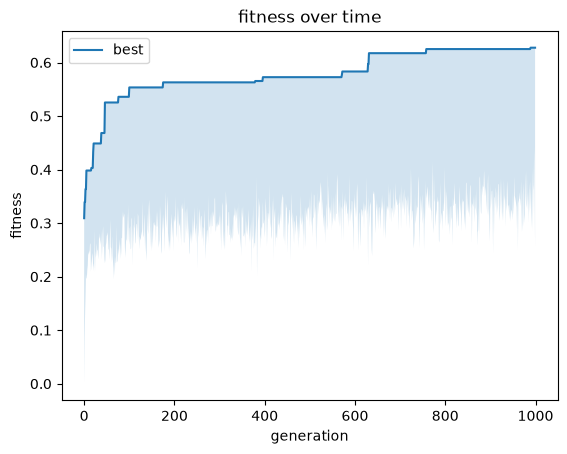

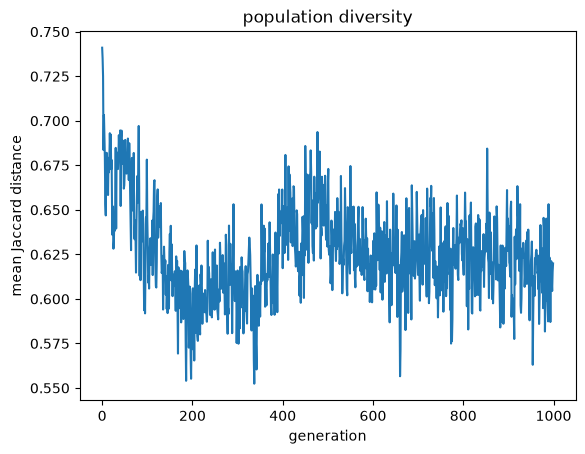

share of children that survive selection, per mutation type:
{'add': 0.347, 'amount': 0.401, 'remove': 0.444, 'swap': 0.369}


In [114]:
%pip install matplotlib
import matplotlib.pyplot as plt

x  = range(GENERATIONS)
plt.plot(x, max_fitnesses, label="best")
plt.fill_between(x, min_fitnesses, max_fitnesses, alpha=0.2)
plt.plot()

plt.xlabel("generation")
plt.ylabel("fitness")
plt.title("fitness over time")
plt.legend()
plt.show()

plt.plot(x, [h["diversity"] for h in history])
plt.xlabel("generation")
plt.ylabel("mean Jaccard distance")
plt.title("population diversity")
plt.show()

print("share of children that survive selection, per mutation type:")
pprint.pprint({m: round(v, 3) for m, v in mutation_survival_rates(history).items()})

In [115]:
# Cookbook titles: the most prominent flavour ingredients, plus the starch when it is not wheat flour.
STRUCTURAL_TYPES = {"starches", "fats", "binders", "leaving_agents", "salts"}

def recipe_title(r: Recipe) -> str:
    flavour_ings = sorted(
        (i for i in r["ingredients"]
         if i.get("type") not in STRUCTURAL_TYPES and i.get("flavour") != "none"),
        key=lambda i: (not i.get("is_indonesian"), -i["amount"]),
    )
    words = [i["name"].title() for i in flavour_ings[:3]]
    if len(words) > 1:
        flavour = ", ".join(words[:-1]) + " & " + words[-1]
    else:
        flavour = words[0] if words else "Plain"
    starches = [i["name"] for i in r["ingredients"] if i.get("type") == "starches"]
    base = f" {starches[0].title()}" if starches and starches[0] != "flour" else ""
    return f"{flavour}{base} Cookies"

for recipe in unique_recipes(population)[:5]:
    recipe["title"] = recipe_title(recipe)
    pprint.PrettyPrinter(indent=2, depth=3).pprint(recipe)

{ 'fitness': 0.6276689475837995,
  'ingredients': [ { 'amount': 2,
                     'cons': 'SOLID',
                     'flavour': 'salt',
                     'is_indonesian': False,
                     'name': 'salt',
                     'source': 'Peanutbutter Sandwich Cookies',
                     'type': 'salts',
                     'unit': 'ml'},
                   { 'amount': 29,
                     'cons': 'SOLID',
                     'flavour': 'none',
                     'is_indonesian': True,
                     'name': 'banana leaf',
                     'source': 'Kue Kacamata (Mata Roda)',
                     'type': 'produce',
                     'unit': 'g'},
                   { 'amount': 10,
                     'cons': 'SOLID',
                     'flavour': 'aromatic',
                     'is_indonesian': True,
                     'name': 'pandan leaf',
                     'source': 'Kue Cucur Jawa',
                     'type': 'produce',
      

### Comparing runs

Runs the evolution with several random seeds, writes the fitness per generation to `runs/fitness_log.csv` and plots the best fitness of each run.

In [ ]:
import csv

SEEDS = [0, 1, 2, 3, 4]
log_path = Path("runs/fitness_log.csv")
log_path.parent.mkdir(exist_ok=True)

all_history = []
best_per_seed = {}
for seed in SEEDS:
    seed_population, seed_history = run_evolution(seed=seed, generations=GENERATIONS)
    all_history += seed_history
    best_per_seed[seed] = seed_population[0]

with log_path.open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=list(all_history[0].keys()))
    writer.writeheader()
    writer.writerows(all_history)

for seed in SEEDS:
    plt.plot([h["max"] for h in all_history if h["seed"] == seed], label=f"seed {seed}")
plt.xlabel("generation")
plt.ylabel("best fitness")
plt.title("best fitness per run")
plt.legend()
plt.show()

for seed in SEEDS:
    plt.plot([h["diversity"] for h in all_history if h["seed"] == seed], label=f"seed {seed}")
plt.xlabel("generation")
plt.ylabel("mean Jaccard distance")
plt.title("population diversity per run")
plt.legend()
plt.show()

for seed, best in best_per_seed.items():
    final_diversity = [h["diversity"] for h in all_history if h["seed"] == seed][-1]
    print(f"seed {seed}: fitness {best['fitness']:.3f}  diversity {final_diversity:.2f}  {recipe_title(best)}")

# If the seeds end on different recipes, the fitness has several peaks and the sameness
# within one run is convergence; if they all end on the same recipe, it is the fitness itself.
bests = list(best_per_seed.values())
print("distinct best recipes across seeds:", len(unique_recipes(bests)), "of", len(bests))
print("mutation survival over all runs:", {m: round(v, 3) for m, v in mutation_survival_rates(all_history).items()})